# ACTIVIDAD 04: Ingeniería Inversa

|                |   |
:----------------|---|
| **Nombre**     | Claudio Alejo Encarnación Martínez  |
| **Fecha**      |  8 octubre 2026 |
| **Expediente** |  750597 | 

### Importación del dataset

El dataset flw contiene imágenes de diferentes personas en diferentes poses, ángulos e iluminaciones, para entrenar y evaluar modelos de reconocimiento facial.

In [1]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
(1348, 62, 47)


Se guarda en la variable `faces` las imágenes de todas aquellas personas en el dataset que tengan al menos 60 imágenes diferentes. Obtenemos un total de 8 personas distintas, con 1348 imágenes en total. Se supone que la función `fetch_lfw_people` ya procesa y convierte a escala de grises las imágenes. 

### Visualización de las imágenes del dataset

A continuación se visualiza una muestra de las imágenes del dataset:

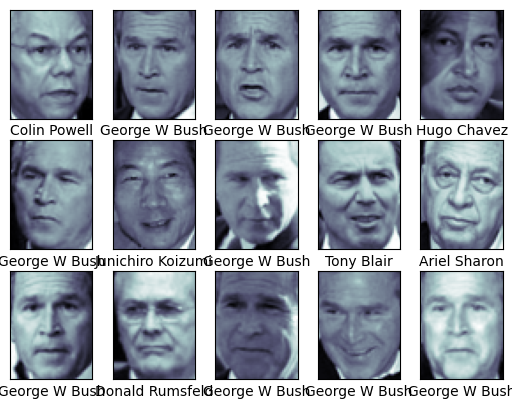

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

### Importación de librerías para la construcción del pipeline

¿Qué es PCA?

Principal Component Analysis (Análisis de Componentes Principales) es una técnica de reducción de dimensionalidad lineal. Transforma tus datos a un nuevo sistema de coordenadas donde:

- La 1ª componente captura la mayor varianza posible. La 2ª componente captura la mayor varianza restante, ortogonal a la 1ª. Y así sucesivamente

- `n_components` Conserva solo las 150 componentes principales. Reduce de 2914 a 150 dimensiones (~95% menos)
- `whiten` Blanquea las componentes: divide cada una por su desviación estándar → todas quedan con varianza = 1
- `random_state` Fija la semilla para el algoritmo aleatorizado (SVD randomizado, mucho más rápido que el exacto)

¿Qué es SVC?

Support Vector Classifier: busca el hiperplano que separa las clases con el margen máximo. Los puntos más cercanos al hiperplano son los vectores de soporte.

- `kernel` Especifica el tipo de kernel a usar en el clasificador SVC. Los valores comunes son `'linear'`, `'poly'`, `'rbf'` y `'sigmoid'`.
- `class_weight` Permite asignar pesos a las clases para manejar desequilibrios en los datos. Puede ser `'balanced'` o un diccionario con pesos específicos para cada clase. (El dataset está desbalanceado: Bush tiene ~530 fotos, Koizumi solo ~60. Sin este parámetro:
El SVM aprende a predecir "Bush" muy seguido.
La accuracy parece buena pero el recall de Koizumi es malísimo.)

¿Qué hace `make_pipeline`?

Crea un Pipeline con los pasos dados, asignando nombres automáticos basados en el tipo de objeto.

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

### Train/test 

In [4]:
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

### GridSearchCV

Prueba todas las combinaciones de una rejilla de hiperparámetros y elige la mejor usando validación cruzada.

`C` es el hiperparámetro de regularización del SVM.
`gamma` es el hiperparámetro del kernel RBF que controla la influencia de cada punto de entrenamiento.

Con 4 valores para cada hiperparámetro, GridSearchCV probará un total de 16 combinaciones (4x4). Que al evaluarse con 5 folds (4 para entrenamiento y 1 para validación), se realizarán 80 entrenamientos en total (16x5).

Genera 16 combinaciones de hiperparámetros. Reentrena hasta conseguir el `best_estimator_` con los mejores hiperparámetros encontrados.

In [5]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)

CPU times: user 51.1 s, sys: 2.57 s, total: 53.7 s
Wall time: 40.1 s
{'svc__C': 5, 'svc__gamma': 0.001}


### Predicción con el mejor estimador encontrado

Una vez que GridSearchCV ha encontrado el mejor estimador (`best_estimator_`)

In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

### Visualización de los resultados del mejor estimador

Una vez que hemos obtenido el mejor estimador mediante GridSearchCV, podemos visualizar su rendimiento en los datos de prueba. A continuación se muestran 24 predicciones aleatorias comparadas con los valores reales, donde si el modelo falló, se indica de color rojo el nombre de la persona.

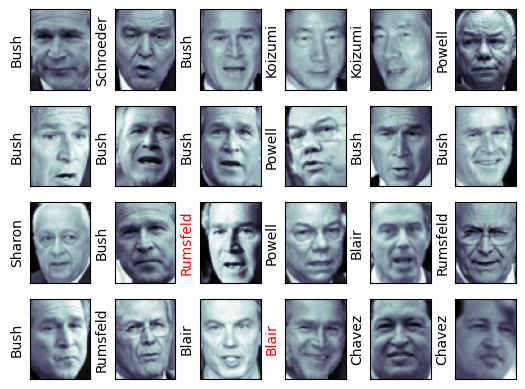

In [12]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')

### Reporte de clasificación

Una vez que hemos evaluado el mejor estimador en los datos de prueba, podemos generar un reporte de clasificación que muestre métricas como precisión, recall y F1-score para cada clase. Esto nos permite entender mejor el rendimiento del modelo en cada categoría.

Parámetros:
- `y_true`: etiquetas reales de los datos de prueba.
- `y_pred`: etiquetas predichas por el modelo.
- `target_names`: nombres de las clases.
- `digits`: número de decimales a mostrar.
- `output_dict`: si se debe devolver un diccionario en lugar de una cadena.
- `zero_division`: valor a usar cuando hay división por cero.

In [8]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



### Matriz de confusión

La diagonal (de arriba-izquierda a abajo-derecha) son los aciertos: fotos donde el modelo dijo exactamente lo correcto. Si la diagonal tiene números grandes, el modelo va bien.

Todo lo que está fuera de la diagonal son errores: fotos que el modelo confundió. Y lo interesante no es solo cuántos errores hay, sino entre qué personas ocurren.

Es importante hacer `mat.T` (la transpuesta de la matriz) si queremos visualizar correctamente la matriz de confusión, ya que algunas implementaciones muestran las filas como predicciones y las columnas como etiquetas reales. Así se lee "el modelo predijo X, pero en realidad era Y"

<Axes: >

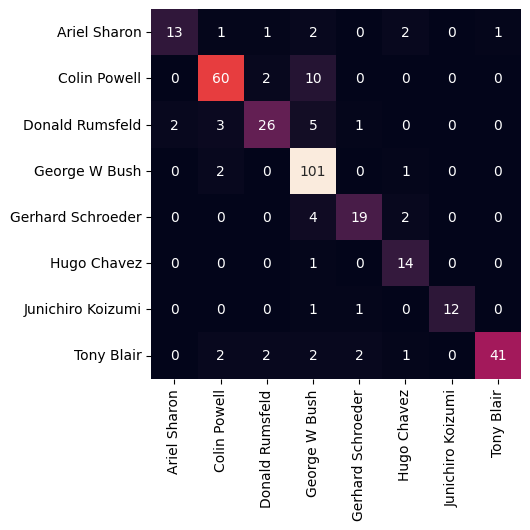

In [9]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)

## Dataset load.digits

El dataset `load.digits` contiene imágenes de dígitos escritos a mano (0-9) y sus etiquetas correspondientes.

Cada imagen es de 8x8 píxeles y está representada como un array de 64 valores (intensidades de píxel). Las etiquetas son números enteros del 0 al 9 que indican qué dígito representa cada imagen.

In [10]:
from sklearn import datasets
data = datasets.load_digits()
print(data.target_names)
print(data.images.shape)

[0 1 2 3 4 5 6 7 8 9]
(1797, 8, 8)


### Visualización 

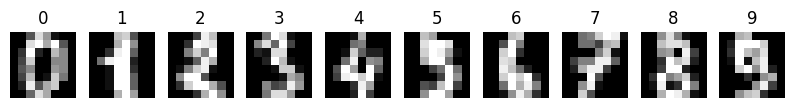

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 10, figsize=(10, 1))
for i in range(10):
    axes[i].imshow(data.images[i], cmap='gray')
    axes[i].set_title(data.target[i])
    axes[i].axis('off')
plt.show()

### Pipeline

In [19]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca_digits = RandomizedPCA(n_components=40, whiten=True, random_state=42)
svc_digits = SVC(kernel='rbf', class_weight='balanced')
model_digits = make_pipeline(pca_digits, svc_digits)

### Train/test

In [20]:
from sklearn.model_selection import train_test_split
Xtrain_digits, Xtest_digits, ytrain_digits, ytest_digits = train_test_split(data.data, data.target, random_state=42)

### GridSearchCV

In [21]:
from sklearn.model_selection import GridSearchCV
param_grid_digits = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid_digits = GridSearchCV(model_digits, param_grid_digits)

%time grid_digits.fit(Xtrain_digits, ytrain_digits)
print(grid_digits.best_params_)

CPU times: user 13 s, sys: 405 ms, total: 13.4 s
Wall time: 20.7 s
{'svc__C': 5, 'svc__gamma': 0.005}


### Predicción

In [23]:
model_digits_ = grid_digits.best_estimator_
yfit_digits = model_digits_.predict(Xtest_digits)

### Visualización de los resultados de la predicción

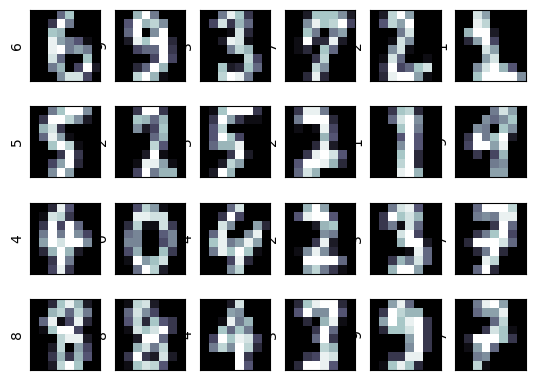

In [26]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest_digits[i].reshape(8, 8), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(data.target_names[yfit_digits[i]],
                   color='black' if yfit_digits[i] == ytest_digits[i] else 'red')

### Reporte de clasificación

In [28]:
from sklearn.metrics import classification_report

print(classification_report(
    ytest_digits,
    yfit_digits,
    target_names=[str(name) for name in data.target_names]
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        38
           3       1.00      0.96      0.98        46
           4       1.00      1.00      1.00        55
           5       0.97      1.00      0.98        59
           6       1.00      0.98      0.99        45
           7       1.00      0.98      0.99        41
           8       0.95      1.00      0.97        38
           9       0.98      0.98      0.98        48

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450



### Matriz de confusión

<Axes: >

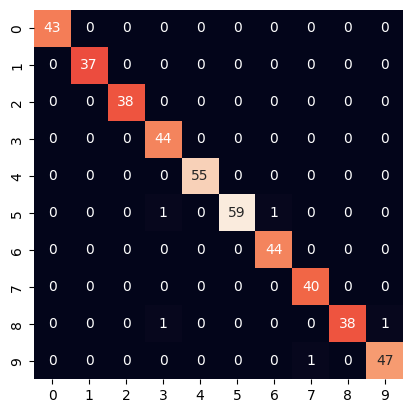

In [30]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
mat_digits = confusion_matrix(ytest_digits, yfit_digits)
sns.heatmap(mat_digits.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=data.target_names,
            yticklabels=data.target_names)

## References

1. Scikit-learn developers. (n.d.). sklearn.datasets.fetch_lfw_people. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_lfw_people.html#sklearn.datasets.fetch_lfw_people

2. Scikit-learn developers. (n.d.). SVM kernels. Scikit-learn. https://scikit-learn.org/stable/modules/svm.html#svm-kernels

3. Scikit-learn developers. (n.d.). sklearn.svm.SVC. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

4. Scikit-learn developers. (n.d.). sklearn.decomposition.PCA. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA